# Module 01 · Economic and survey baseline
**Purpose:** build a monthly baseline beginning January 2010, issue genuinely out-of-sample economic-only sentiment predictions, and preserve everything needed to rerun or update the analysis. No LLM calls or paid scoring.

Run top to bottom in a fresh Colab notebook. Edit only the configuration cell first. You need **free BEA and FRED API keys**; BLS does not require a key for the short requests used here. Keys are entered securely and never written into outputs. Official registration: [BEA](https://apps.bea.gov/api/signup/) · [FRED](https://fred.stlouisfed.org/docs/api/api_key.html).

**Two distinct datasets:**
* Current official history: Michigan's three survey indices, BLS seasonally adjusted U-3, BEA PCE price index and quarterly real GDP. This dataset is for description and source checking.
* Historical information sets: ALFRED/FRED archives of the original BLS/BEA series, with revision intervals. Only data archived before each origin enter predictions. Current official downloads NEVER replace missing historical vintages.

**Timing convention:** a prediction for month t is issued at the start of that month, using data available through the preceding day. A one-day archive buffer excludes same-day release ambiguity. This is a monthly forecast, not an explanation using all information released during the survey month. A media module must use information available before that same origin.

**Important limits:** archive effective dates are not necessarily the original publisher's release timestamp. The module preserves both, downloads release calendars, flags unmatched dates, and leaves unverified publisher timestamps blank. The headline forecasting outcome is the **first nonmissing archived UMCSENT observation**, explicitly not guaranteed to be Michigan's preliminary or final first publication. Public Michigan files supply all three current survey histories. Component forecasts require genuine historical component-release records; the module never invents them or backdates today's component file.

In [ ]:
# Colab setup. Comment out the pip line if your environment already has these packages.
# %pip -q install pandas==2.2.3 numpy==2.2.6 scipy==1.15.3 matplotlib==3.10.3
from pathlib import Path
import os, json, io, hashlib, getpass, time, platform, importlib.metadata
import urllib.request, urllib.parse, urllib.error
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import numpy as np
from scipy.stats import t as student_t
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [ ]:
#D8900CCD-0539-4CBC-B2A4-3C2B21573D98 - BEA
#e6509d251d81de4fad42b7e40403ddc0

In [ ]:
# EDIT: the new project folder you create in Drive.
PROJECT_ROOT = Path('/content/drive/MyDrive/NLP-FinalProject')
START_MONTH = '2010-01'
# This is a retrieval cutoff, not a claim that current-month releases are complete.
AS_OF = datetime.now(ZoneInfo('America/New_York')).date().isoformat()
SNAPSHOT_ID = AS_OF          # same ID reruns saved raw responses; change for a fresh retrieval
FIRST_OOS_MONTH = '2015-01'   # five years of initial estimation
MONITOR_START = '2026-07'
MONITOR_END = '2026-10'       # focused pre-election monitoring window
MIN_TRAIN = 48
INTERVAL_ALPHA = .05         # nominal 95% observation prediction interval
ARCHIVE_BUFFER_DAYS = 1
OBSERVATION_START = '2006-01-01' # warmup for 12-month rates and 36-month price change
RUN_DIRECT_DOWNLOADS = True
# Optional CSV of VERIFIED historical survey releases, including components.
# Columns: target, observation_month, value, available_date, release_stage, source_url.
# target is sentiment/current_conditions/expectations. Do not upload today's history with guessed dates.
SURVEY_RELEASES_CSV = None

BASE = PROJECT_ROOT/'01_economic_baseline'
RAW = BASE/'raw'/SNAPSHOT_ID
PROCESSED = BASE/'processed'/SNAPSHOT_ID
RESULTS = BASE/'results'/SNAPSHOT_ID
for folder in [RAW,PROCESSED,RESULTS]: folder.mkdir(parents=True,exist_ok=True)
CONFIG = dict(start_month=START_MONTH,as_of=AS_OF,snapshot_id=SNAPSHOT_ID,
    first_oos_month=FIRST_OOS_MONTH,monitor_start=MONITOR_START,monitor_end=MONITOR_END,
    min_train=MIN_TRAIN,interval_alpha=INTERVAL_ALPHA,archive_buffer_days=ARCHIVE_BUFFER_DAYS,
    observation_start=OBSERVATION_START,origin_rule='month start; previous-day archive cutoff',
    target_rule='first archived headline value; optional verified component releases',
    survey_releases_csv=str(SURVEY_RELEASES_CSV) if SURVEY_RELEASES_CSV else None)
config_path=RAW/'config.json'
if config_path.exists() and json.loads(config_path.read_text())!=CONFIG:
    raise ValueError('Snapshot configuration differs. Use a new SNAPSHOT_ID to preserve the old run.')
config_path.write_text(json.dumps(CONFIG,indent=2))
BEA_KEY=os.environ.get('BEA_API_KEY') or (getpass.getpass('Free BEA API key: ') if RUN_DIRECT_DOWNLOADS else '')
FRED_KEY=os.environ.get('FRED_API_KEY') or getpass.getpass('Free FRED API key: ')
print('Snapshot:',SNAPSHOT_ID,'| outputs:',BASE)

Free BEA API key: ··········
Free FRED API key: ··········
Snapshot: 2026-10-16 | outputs: /content/drive/MyDrive/NLP-FinalProject/01_economic_baseline


## 1. Source definitions and audit trail
U-3 is unemployed persons as a percentage of the civilian labor force, seasonally adjusted; it is not the nonemployment share. Michigan measures personal finances, business conditions and buying conditions, including expectations—not a direct rating of GDP, unemployment and inflation alone.

PCE inflation: **100 × (PCEPIₘ/PCEPIₘ₋₁₂ − 1)**. GDP growth is calculated from quarterly real levels in two separately named columns: **100 × [(GDPq/GDPq₋₁)⁴ − 1]** (quarter-over-quarter annualized) and **100 × (GDPq/GDPq₋₄ − 1)** (year over year).

Controls are deliberately small: cumulative PCE price increases over 36 months and the U-6 minus U-3 labor-underutilization gap. Add them one at a time, then jointly; do not search dozens of controls for a preferred answer. Real household income, housing affordability, debt burdens and policy uncertainty remain alternative omitted explanations, not variables this module silently claims to measure.

In [ ]:
SOURCES = {
 'UMCSENT':dict(name='Michigan headline sentiment',agency='University of Michigan',frequency='M',
    official_url='https://www.sca.isr.umich.edu/tables.html',units='Index 1966Q1=100'),
 'UNRATE':dict(name='U-3 unemployment',agency='BLS',frequency='M',
    official_url='https://www.bls.gov/cps/',units='Percent, seasonally adjusted',bls_id='LNS14000000'),
 'PCEPI':dict(name='Headline PCE price index',agency='BEA',frequency='M',
    official_url='https://www.bea.gov/data/personal-consumption-expenditures-price-index',
    units='Chain-type index, seasonally adjusted',bea_table='T20804',bea_line='1'),
 'GDPC1':dict(name='Real GDP',agency='BEA',frequency='Q',
    official_url='https://www.bea.gov/data/gdp/gross-domestic-product',
    units='Chained dollars, seasonally adjusted annual rate',bea_table='T10106',bea_line='1'),
 'U6RATE':dict(name='U-6 labor underutilization',agency='BLS',frequency='M',
    official_url='https://www.bls.gov/cps/lfcharacteristics.htm',units='Percent, seasonally adjusted')}
pd.DataFrame(SOURCES).T.to_csv(PROCESSED/'series_dictionary.csv',index_label='series_id')

# Cached HTTP responses: secrets excluded from metadata, filenames and raised errors.
def fetch_bytes(name,url,params=None,payload=None):
    params=params or {}
    path=RAW/name
    if path.exists(): return path.read_bytes()
    safe={k:v for k,v in params.items() if k.lower() not in {'api_key','userid','registrationkey'}}
    full=url+('?' + urllib.parse.urlencode(params) if params else '')
    data=None if payload is None else json.dumps(payload).encode()
    request=urllib.request.Request(full,data=data,headers={'User-Agent':'Academic economic baseline module',
        **({'Content-Type':'application/json'} if data is not None else {})})
    try:
        with urllib.request.urlopen(request,timeout=60) as response: body=response.read()
    except Exception as e:
        raise RuntimeError(f'{name}: download failed ({type(e).__name__}); check access/key and rerun.') from None
    temporary=path.with_suffix(path.suffix+'.tmp');temporary.write_bytes(body);temporary.replace(path)
    metadata=dict(endpoint=url,parameters=safe,retrieved_at_utc=datetime.now(ZoneInfo('UTC')).isoformat(),
        sha256=hashlib.sha256(body).hexdigest(),size_bytes=len(body))
    path.with_suffix(path.suffix+'.meta.json').write_text(json.dumps(metadata,indent=2))
    return body

def fetch_json(name,url,params=None,payload=None):
    data=json.loads(fetch_bytes(name,url,params,payload))
    if 'error_code' in data: raise ValueError(f'{name}: API rejected request; check key and series.')
    return data

## 2. Download current official histories
These direct downloads satisfy source provenance and reveal current historical values. They do **not** contain historical information sets. Raw responses are preserved. If a source fails, fix the access issue and rerun; no substitute data are inserted.

In [ ]:
def load_michigan():
    frames=[]
    for filename,mapping in [('tbmics.csv',{'ICS_ALL':'sentiment'}),
                             ('tbmiccice.csv',{'ICC':'current_conditions','ICE':'expectations'})]:
        body=fetch_bytes('michigan_'+filename,'https://www.sca.isr.umich.edu/files/'+filename)
        df=pd.read_csv(io.BytesIO(body))
        required={'Month','YYYY',*mapping}
        if not required.issubset(df): raise ValueError(f'Michigan schema changed: {list(df)}')
        dates=pd.to_datetime(df.Month.astype(str)+' '+df.YYYY.astype(str),format='%B %Y',errors='coerce')
        df=df.rename(columns=mapping).assign(observation_month=dates)
        for target in mapping.values(): df[target]=pd.to_numeric(df[target],errors='coerce')
        frames.append(df[['observation_month',*mapping.values()]].dropna(subset=['observation_month']))
    out=frames[0].merge(frames[1],on='observation_month',how='outer',validate='one_to_one').sort_values('observation_month')
    out=out.loc[(out.observation_month>=START_MONTH)&(out.observation_month<=AS_OF)].copy()
    out['retrieval_as_of']=AS_OF
    out['release_status']='Latest public file; latest month may be preliminary; publisher date not inferred'
    return out

def load_bls():
    rows=[]
    # <=10 years/request; no BLS registration needed for these requests.
    for first in range(int(OBSERVATION_START[:4]),int(AS_OF[:4])+1,10):
        last=min(first+9,int(AS_OF[:4]))
        d=fetch_json(f'bls_{first}_{last}.json','https://api.bls.gov/publicAPI/v2/timeseries/data/',
            payload={'seriesid':['LNS14000000'],'startyear':str(first),'endyear':str(last)})
        if d.get('status')!='REQUEST_SUCCEEDED': raise ValueError('BLS request failed; inspect saved response.')
        for series in d['Results']['series']:
            assert series['seriesID']=='LNS14000000'
            for r in series['data']:
                if r['period'].startswith('M') and 1<=int(r['period'][1:])<=12:
                    rows.append({
                                  'observation_period': f"{r['year']}-{r['period'][1:]}-01",
                                  'u3': pd.to_numeric(r['value'], errors='coerce')
                              })
    return pd.DataFrame(rows).drop_duplicates('observation_period').sort_values('observation_period')

def load_bea(table,frequency):
    params=dict(UserID=BEA_KEY,method='GetData',datasetname='NIPA',TableName=table,
                Frequency=frequency,Year=','.join(str(y) for y in range(int(OBSERVATION_START[:4]),int(AS_OF[:4])+1)),ResultFormat='JSON')
    d=fetch_json(f'bea_{table}.json','https://apps.bea.gov/api/data/',params)
    results=d.get('BEAAPI',{}).get('Results',{})
    if isinstance(results,list): results=results[0]
    if 'Error' in results or 'Data' not in results: raise ValueError(f'BEA {table}: inspect saved API error; check key/table.')
    frame=pd.DataFrame(results['Data'])
    frame=frame.loc[frame.LineNumber.astype(str).eq('1')].copy()
    if frame.empty: raise ValueError(f'No line 1 in {table}')
    expected='personal consumption expenditures' if table=='T20804' else 'gross domestic product'
    if not frame.LineDescription.str.lower().str.contains(expected,regex=False).all():
        raise ValueError('BEA line meaning changed; review metadata before continuing.')
    def period(s):
        return pd.Period(s.replace('M','-'),freq='M').to_timestamp() if frequency=='M' else pd.Period(s,freq='Q').to_timestamp()
    frame['observation_period']=frame.TimePeriod.map(period)
    frame['value']=pd.to_numeric(frame.DataValue.str.replace(',','',regex=False),errors='coerce')
    return frame[['observation_period','value','TimePeriod','LineDescription','METRIC_NAME','CL_UNIT','UNIT_MULT']].sort_values('observation_period')

survey_current=load_michigan()
survey_current.to_csv(PROCESSED/'survey_three_indices_current.csv',index=False)
if RUN_DIRECT_DOWNLOADS:
    bls_current=load_bls();bls_current.to_csv(PROCESSED/'bls_u3_current.csv',index=False)
    pce_current=load_bea('T20804','M');pce_current.to_csv(PROCESSED/'bea_pce_current.csv',index=False)
    gdp_current=load_bea('T10106','Q');gdp_current.to_csv(PROCESSED/'bea_real_gdp_quarterly_current.csv',index=False)
    p=pce_current.set_index('observation_period').value.asfreq('MS')
    current=survey_current.set_index('observation_month').join(bls_current.assign(observation_period=lambda x:pd.to_datetime(x.observation_period)).set_index('observation_period'))
    current['pce_price_index']=p
    current['pce_yoy_pct']=100*(p/p.shift(12)-1)
    current.to_csv(PROCESSED/'monthly_current_official.csv',index_label='observation_month')
    q=gdp_current.set_index('observation_period').value.asfreq('QS')
    quarterly=pd.DataFrame({'real_gdp':q,'gdp_qoq_annualized_pct':100*((q/q.shift(1))**4-1),'gdp_yoy_pct':100*(q/q.shift(4)-1)})
    quarterly.to_csv(PROCESSED/'gdp_current_quarterly_growth.csv')
else: print('Direct BLS/BEA downloads disabled. Run these before presenting the source-complete module.')
display(survey_current.tail())

,observation_month,sentiment,current_conditions,expectations,retrieval_as_of,release_status
677,2026-05-01,44.8,45.8,44.1,2026-10-16,Latest public file; latest month may be prelim...
678,2026-06-01,49.5,47.7,50.7,2026-10-16,Latest public file; latest month may be prelim...
679,2026-07-01,55.2,54.8,55.4,2026-10-16,Latest public file; latest month may be prelim...
680,2026-08-01,51.7,51.9,51.5,2026-10-16,Latest public file; latest month may be prelim...
681,2026-09-01,48.1,50.9,46.3,2026-10-16,Latest public file; latest month may be prelim...


## 3. Download revision histories and release calendars
The FRED API is used to retrieve **ALFRED historical vintages of BLS/BEA/Michigan data**, not to substitute current data for past releases. `output_type=1` with an explicit historical real-time interval preserves values and their validity intervals. Responses are paginated and cached.

For each observation, `realtime_start` and `realtime_end` describe the archive validity interval. `archive_available_date` is one day after its start by default. A matching FRED release-calendar date is recorded as a candidate publication date. An unmatched revision can be a correction or archive update; the module leaves its publication date unknown rather than guessing. This remains a date-level archive-based exercise, not a fully verified publisher-timestamp reconstruction.

In [ ]:
FRED_BASE='https://api.stlouisfed.org/fred/'
FRED_AS_OF = min(
    AS_OF,
    datetime.now(ZoneInfo("America/Chicago")).date().isoformat(),
)
def fred(endpoint,name,**params):
    if params.get("realtime_end") == AS_OF:
      params["realtime_end"] = FRED_AS_OF

    if params.get("observation_end") == AS_OF:
        params["observation_end"] = FRED_AS_OF
    return fetch_json(name,FRED_BASE+endpoint,dict(api_key=FRED_KEY,file_type='json',**params))

def download_vintages(series_id):
    collected=[]; offset=0
    while True:
        d=fred('series/observations',f'{series_id}_vintages_{offset}.json',series_id=series_id,
          observation_start=OBSERVATION_START,observation_end=AS_OF,
          realtime_start='1776-07-04',realtime_end=AS_OF,output_type=1,
          limit=100000,offset=offset)
        part=d.get('observations',[])
        collected.extend(part)
        offset+=len(part)
        if offset>=int(d.get('count',0)) or not part: break
    if not collected: raise ValueError(f'{series_id}: no archive observations; do not replace with current history.')
    df=pd.DataFrame(collected).rename(columns={'date':'observation_period','realtime_start':'vintage_start','realtime_end':'vintage_end'})
    df['value']=pd.to_numeric(df.value,errors='coerce')
    df['series_id']=series_id
    df['observation_period']=pd.to_datetime(df.observation_period)
    df['vintage_start']=pd.to_datetime(df.vintage_start)
    # FRED's 9999-12-31 end sentinel is stored as text; avoid pandas overflow.
    df['vintage_end']=df.vintage_end.astype(str)
    df['archive_available_date']=df.vintage_start+pd.Timedelta(days=ARCHIVE_BUFFER_DAYS)
    df=df.sort_values(['observation_period','vintage_start']).drop_duplicates(['observation_period','vintage_start'])
    df['archive_revision_number']=df.groupby('observation_period').cumcount()
    # These are archive revision numbers, NOT BEA advance/second/third labels.
    release=fred('series/release',f'{series_id}_release.json',series_id=series_id)
    releases=release.get('releases',[])
    dates=set()
    if releases:
        rid=releases[0]['id'];offset=0
        while True:
            calendar=fred('release/dates',f'release_{rid}_dates_{offset}.json',release_id=rid,
                realtime_start='1776-07-04',realtime_end=AS_OF,include_release_dates_with_no_data='true',
                limit=1000,offset=offset)
            part=calendar.get('release_dates',[])
            dates.update(r['date'] for r in part)
            offset+=len(part)
            if offset>=int(calendar.get('count',0)) or not part: break
    df['publication_date_from_calendar']=df.vintage_start.dt.strftime('%Y-%m-%d').where(df.vintage_start.dt.strftime('%Y-%m-%d').isin(dates),'')
    df['publisher_timestamp_verified']=False
    df['publisher_release_timestamp']=''
    df['publication_date_basis']=np.where(df.publication_date_from_calendar.ne(''),'Archive vintage date matches FRED release calendar','Unknown publisher date; archive date only')
    df['original_agency']=SOURCES[series_id]['agency']
    df['official_source_url']=SOURCES[series_id]['official_url']
    df.to_csv(PROCESSED/f'{series_id}_revision_ledger.csv',index=False)
    return df

vintages={}
for sid in SOURCES:
    vintages[sid]=download_vintages(sid)
    print(sid,':',len(vintages[sid]),'revision records')
ledger=pd.concat(vintages.values(),ignore_index=True)
ledger.to_csv(PROCESSED/'all_revision_records.csv',index=False)
publication_audit=ledger.groupby(['series_id','publication_date_basis']).size().rename('records').reset_index()
publication_audit.to_csv(RESULTS/'publication_date_audit.csv',index=False)
display(publication_audit)

UMCSENT : 260 revision records
UNRATE : 465 revision records
PCEPI : 2402 revision records
GDPC1 : 770 revision records
U6RATE : 519 revision records


,series_id,publication_date_basis,records
0,GDPC1,Archive vintage date matches FRED release cale...,770
1,PCEPI,Archive vintage date matches FRED release cale...,2402
2,U6RATE,Archive vintage date matches FRED release cale...,519
3,UMCSENT,Archive vintage date matches FRED release cale...,260
4,UNRATE,Archive vintage date matches FRED release cale...,465


## 4. Construct each historical information set
Each row has a **target month**, **forecast origin**, **archive cutoff**, and the observation period and vintage of every feature. PCE numerator and denominator come from the same as-of snapshot. GDP is the latest published completed quarter at the origin, carried as a known information feature; it is never a synthetic monthly GDP observation.

A missing vintage or stale series is flagged. The model cannot silently fall back to today's history. Monthly features older than four months or GDP older than nine months are marked stale and not used for fitting that row.

In [ ]:
def snapshot(df,cutoff):
    cutoff=pd.Timestamp(cutoff)
    # Buffer implements availability after the archived effective day; no intraday precision claimed.
    archive_day=cutoff-pd.Timedelta(days=ARCHIVE_BUFFER_DAYS)
    mask=(df.vintage_start<=archive_day)&(df.vintage_end>=archive_day.strftime('%Y-%m-%d'))
    result=df.loc[mask & df.value.notna()].sort_values(['observation_period','vintage_start'])
    return result.drop_duplicates('observation_period',keep='last').set_index('observation_period')

def latest_monthly(df,cutoff):
    s=snapshot(df,cutoff)
    s=s.loc[s.index<pd.Timestamp(cutoff).to_period('M').to_timestamp()]
    return s

def build_information_row(month,vintage_data):
    month=pd.Timestamp(month);cutoff=month-pd.Timedelta(days=1)
    out={'observation_month':month,'forecast_origin':month,'information_cutoff':cutoff}
    problems=[]
    def record(prefix,frame):
        if frame.empty:
            problems.append(prefix+': missing');return None
        r=frame.iloc[-1];obs=frame.index[-1]
        out[prefix+'_observation_period']=obs
        out[prefix+'_vintage_start']=r.vintage_start
        out[prefix+'_available_date']=r.archive_available_date
        out[prefix+'_publication_date']=r.publication_date_from_calendar
        age=(month.year-obs.year)*12+month.month-obs.month
        out[prefix+'_age_months']=age
        return obs,r
    un=latest_monthly(vintage_data['UNRATE'],cutoff)
    latest=record('u3',un)
    if latest:
        obs,r=latest;out['u3']=r.value
        if out['u3_age_months']>4: problems.append('u3 stale')
    pce=latest_monthly(vintage_data['PCEPI'],cutoff)
    latest=record('pce',pce)
    if latest:
        obs,r=latest
        prior=obs-pd.DateOffset(months=12);base=obs-pd.DateOffset(months=36)
        out['pce_price_index']=r.value
        out['pce_yoy_pct']=100*(r.value/pce.at[prior,'value']-1) if prior in pce.index else np.nan
        out['pce_cumulative_36m_pct']=100*(r.value/pce.at[base,'value']-1) if base in pce.index else np.nan
        if out['pce_age_months']>4: problems.append('pce stale')
        # Audit the denominator vintages, not just the latest index observation.
        for tag,date in [('pce_12m_denominator',prior),('pce_36m_denominator',base)]:
            if date in pce.index:
                out[tag+'_observation_period']=date
                out[tag+'_vintage_start']=pce.at[date,'vintage_start']
    gdp=snapshot(vintage_data['GDPC1'],cutoff)
    gdp=gdp.loc[(gdp.index+pd.offsets.QuarterEnd(0))<month]
    latest=record('gdp',gdp)
    if latest:
        obs,r=latest
        prev=obs-pd.DateOffset(months=3);year=obs-pd.DateOffset(months=12)
        out['gdp_qoq_annualized_pct']=100*((r.value/gdp.at[prev,'value'])**4-1) if prev in gdp.index else np.nan
        out['gdp_yoy_pct']=100*(r.value/gdp.at[year,'value']-1) if year in gdp.index else np.nan
        if out['gdp_age_months']>9: problems.append('gdp stale')
        for tag,date in [('gdp_qoq_denominator',prev),('gdp_yoy_denominator',year)]:
            if date in gdp.index:
                out[tag+'_observation_period']=date
                out[tag+'_vintage_start']=gdp.at[date,'vintage_start']
    u6=latest_monthly(vintage_data['U6RATE'],cutoff)
    common=un.index.intersection(u6.index)
    if len(common):
        obs=common[-1]
        out['underutilization_gap_pp']=u6.at[obs,'value']-un.at[obs,'value']
        out['underutilization_observation_period']=obs
        out['underutilization_available_date']=max(u6.at[obs,'archive_available_date'],un.at[obs,'archive_available_date'])
        if (month.year-obs.year)*12+month.month-obs.month>4: out['underutilization_gap_pp']=np.nan
    out['information_issues']='; '.join(problems)
    return out

months=pd.date_range(START_MONTH,pd.Timestamp(AS_OF).to_period('M').to_timestamp(),freq='MS')
information=pd.DataFrame([build_information_row(m,vintages) for m in months])
for c in information:
    if c.endswith('_available_date'):
        assert (information[c].isna() | (information[c]<=information.information_cutoff)).all(),f'Future information in {c}'
information.to_csv(PROCESSED/'monthly_information_sets.csv',index=False)
display(information.tail(8))

,observation_month,forecast_origin,information_cutoff,u3_observation_period,u3_vintage_start,u3_available_date,u3_publication_date,u3_age_months,u3,pce_observation_period,...,gdp_qoq_annualized_pct,gdp_yoy_pct,gdp_qoq_denominator_observation_period,gdp_qoq_denominator_vintage_start,gdp_yoy_denominator_observation_period,gdp_yoy_denominator_vintage_start,information_issues,underutilization_gap_pp,underutilization_observation_period,underutilization_available_date
194,2026-03-01,2026-03-01,2026-02-28,2026-01-01,2026-02-11,2026-02-12,2026-02-11,2,4.3,2025-12-01,...,1.422544,2.227067,2025-07-01,2026-01-22,2024-10-01,2025-09-25,,3.7,2026-01-01,2026-02-12
195,2026-04-01,2026-04-01,2026-03-31,2026-02-01,2026-03-06,2026-03-07,2026-03-06,2,4.4,2026-01-01,...,0.652898,2.032574,2025-07-01,2026-01-22,2024-10-01,2025-09-25,,3.5,2026-02-01,2026-03-07
196,2026-05-01,2026-05-01,2026-04-30,2026-03-01,2026-04-03,2026-04-04,2026-04-03,2,4.3,2026-02-01,...,0.482248,1.989300,2025-07-01,2026-01-22,2024-10-01,2025-09-25,,3.7,2026-03-01,2026-04-04
197,2026-06-01,2026-06-01,2026-05-31,2026-04-01,2026-05-08,2026-05-09,2026-05-08,2,4.3,2026-04-01,...,1.621137,2.566845,2025-10-01,2026-04-09,2025-01-01,2025-09-25,,3.9,2026-04-01,2026-05-09
198,2026-07-01,2026-07-01,2026-06-30,2026-05-01,2026-06-05,2026-06-06,2026-06-05,2,4.3,2026-05-01,...,2.089189,2.684743,2025-10-01,2026-04-09,2025-01-01,2025-09-25,,3.8,2026-05-01,2026-06-06
199,2026-08-01,2026-08-01,2026-07-31,2026-06-01,2026-07-02,2026-07-03,2026-07-02,2,4.2,2026-06-01,...,1.500152,2.101819,2026-01-01,2026-06-25,2025-04-01,2025-09-25,,3.7,2026-06-01,2026-07-03
200,2026-09-01,2026-09-01,2026-08-31,2026-07-01,2026-08-07,2026-08-08,2026-08-07,2,4.1,2026-07-01,...,1.483659,2.097672,2026-01-01,2026-06-25,2025-04-01,2025-09-25,,3.8,2026-07-01,2026-08-08
201,2026-10-01,2026-10-01,2026-09-30,2026-08-01,2026-09-04,2026-09-05,2026-09-04,2,4.1,2026-07-01,...,1.483659,2.097672,2026-01-01,2026-06-25,2025-04-01,2025-09-25,,3.6,2026-08-01,2026-09-05


## 5. Define observed survey outcomes and their availability
Headline: choose the first nonmissing UMCSENT archive record for each survey month. Preserve its date, archive stage and value. That date can lag Michigan's release; the buffer is conservative. At each forecast origin, only outcomes already available enter training or residual calibration. Current-month unreleased outcomes stay blank.

Components: descriptive histories are already exported separately. If you supply a verified historical release CSV, component first-release outcomes and separate forecasts are enabled. Otherwise their historical forecast status is explicitly unavailable. You can also supply a consistent verified final-release headline ledger to replace the archive-first outcome; that changes the experiment and requires a new snapshot.

In [ ]:
headline=vintages['UMCSENT'].loc[lambda x:x.value.notna()].sort_values(['observation_period','vintage_start']).drop_duplicates('observation_period',keep='first')
outcomes=headline[['observation_period','value','archive_available_date','official_source_url']].rename(
    columns={'observation_period':'observation_month','archive_available_date':'available_date','official_source_url':'source_url'})
outcomes['target']='sentiment';outcomes['release_stage']='first nonmissing ALFRED archive record; preliminary/final not asserted'
if SURVEY_RELEASES_CSV:
    extra=pd.read_csv(SURVEY_RELEASES_CSV)
    need={'target','observation_month','value','available_date','release_stage','source_url'}
    if not need.issubset(extra): raise ValueError(f'Missing survey-ledger columns: {need-set(extra)}')
    extra['observation_month']=pd.to_datetime(extra.observation_month).dt.to_period('M').dt.to_timestamp()
    extra['available_date']=pd.to_datetime(extra.available_date)
    extra['value']=pd.to_numeric(extra.value,errors='raise')
    assert extra.target.isin(['sentiment','current_conditions','expectations']).all()
    assert extra.source_url.fillna('').str.startswith('https://').all(), 'Evidence URL required.'
    extra=extra.sort_values('available_date').drop_duplicates(['target','observation_month'],keep='first')
    outcomes=outcomes.loc[~outcomes.target.isin(extra.target.unique())]
    outcomes=pd.concat([outcomes,extra[list(need)]],ignore_index=True)
outcomes=outcomes.loc[outcomes.available_date<=pd.Timestamp(AS_OF)].copy()
assert not outcomes.duplicated(['target','observation_month']).any()
assert (outcomes.available_date>=outcomes.observation_month).all()
outcomes.to_csv(PROCESSED/'survey_forecast_outcomes.csv',index=False)
print('Forecast targets available:',outcomes.target.unique().tolist())
print('Components remain descriptive unless a historical release ledger was supplied.')

Forecast targets available: ['sentiment']
Components remain descriptive unless a historical release ledger was supplied.


## 6. Expanding-window economic-only forecasts
The core model uses U-3, headline PCE YoY inflation and the latest released quarterly real GDP growth. Historical feature rows stay frozen at their own forecast origins. Training begins in 2010; out-of-sample predictions begin in 2015, subject to at least 48 complete training observations. No random train/test split, test-month tuning or future outcome imputation.

Compare a training-mean benchmark, a last-available-sentiment benchmark, the economic baseline, cumulative-price and underutilization extensions, and a GDP-YoY sensitivity model. A separate persistence-plus-economics model tests whether adding economic variables improves over persistence alone. The primary gap always uses the pre-specified `economic_core` model.

Intervals: nominal 95% **observation prediction intervals** from expanding-window OLS (including residual noise, not confidence bands for the conditional mean). They assume linearity and approximately independent, homoskedastic errors; these assumptions may fail. Also report conservative empirical bands using only past out-of-sample absolute errors available at the origin (minimum 24). Empirical bands have no guaranteed coverage under temporal dependence or regime shifts. Both interval types receive actual out-of-sample coverage checks.

In [ ]:
CORE=['u3','pce_yoy_pct','gdp_qoq_annualized_pct']
SPECS={
 'economic_core':CORE,
 'economic_prices':CORE+['pce_cumulative_36m_pct'],
 'economic_underutilization':CORE+['underutilization_gap_pp'],
 'economic_both_controls':CORE+['pce_cumulative_36m_pct','underutilization_gap_pp'],
 'economic_gdp_yoy':['u3','pce_yoy_pct','gdp_yoy_pct'],
 'economic_plus_persistence':CORE+['last_available_sentiment']}

def fit_predict_ols(train,row,features,alpha=INTERVAL_ALPHA):
    X=train[features].to_numpy(dtype=float);y=train.value.to_numpy(dtype=float)
    mu=X.mean(axis=0);scale=X.std(axis=0)
    if (scale<1e-10).any(): raise ValueError('Constant feature in training sample')
    Z=np.column_stack([np.ones(len(X)),(X-mu)/scale])
    z=np.r_[1.,(row[features].to_numpy(dtype=float)-mu)/scale]
    beta,_,rank,_=np.linalg.lstsq(Z,y,rcond=None)
    if rank<Z.shape[1]: raise ValueError('Rank-deficient design')
    dof=len(y)-Z.shape[1]
    if dof<=0: raise ValueError('Insufficient residual degrees of freedom')
    residual=y-Z@beta;s2=float(residual@residual/dof)
    center=float(z@beta)
    se=np.sqrt(s2*(1+float(z@np.linalg.pinv(Z.T@Z)@z)))
    radius=student_t.ppf(1-alpha/2,dof)*se
    original_beta=beta[1:]/scale
    intercept=beta[0]-original_beta@mu
    return dict(predicted=center,pi_lower=center-radius,pi_upper=center+radius,
                n_train=len(train),coefficients={'intercept':float(intercept),**dict(zip(features,map(float,original_beta)))})

def run_forecasts(info,outcome_table):
    results=[];failures=[]
    for target,ys in outcome_table.groupby('target'):
        rows=info.copy()
        # Persistence features use only outcomes released at each row's origin.
        rows['last_available_sentiment']=np.nan
        for i,r in rows.iterrows():
            known=ys.loc[(ys.available_date<=r.information_cutoff)&(ys.observation_month<r.observation_month)].sort_values('observation_month')
            if not known.empty: rows.at[i,'last_available_sentiment']=known.iloc[-1].value
        data=rows.merge(ys,on='observation_month',how='left',validate='one_to_one')
        # An absent outcome does not prevent issuing a forecast for the current month.
        for _,row in data.loc[data.observation_month>=FIRST_OOS_MONTH].iterrows():
            known=(data.observation_month<row.observation_month)&(data.available_date<=row.information_cutoff)&data.value.notna()
            for model,features in SPECS.items():
                train=data.loc[known & data.information_issues.eq('')].dropna(subset=features)
                if len(train)<MIN_TRAIN or row[features].isna().any() or row.information_issues:
                    failures.append(dict(target=target,model=model,observation_month=str(row.observation_month.date()),reason='Insufficient training, missing feature, or stale information'))
                    continue
                try: fitted=fit_predict_ols(train,row,features)
                except ValueError as e:
                    failures.append(dict(target=target,model=model,observation_month=str(row.observation_month.date()),reason=str(e)));continue
                available=ys.loc[ys.observation_month.eq(row.observation_month)]
                actual=float(available.iloc[0].value) if len(available) else np.nan
                release=available.iloc[0].available_date if len(available) else pd.NaT
                rec=dict(target=target,model=model,observation_month=row.observation_month,
                    forecast_origin=row.forecast_origin,information_cutoff=row.information_cutoff,
                    actual=actual,outcome_available_date=release,**fitted)
                rec['sentiment_gap']=actual-fitted['predicted']
                # Use only completed OOS errors whose outcomes had arrived BEFORE this origin.
                past=[abs(r['sentiment_gap']) for r in results if r['target']==target and r['model']==model
                      and pd.notna(r['outcome_available_date']) and r['outcome_available_date']<=row.information_cutoff
                      and pd.notna(r['sentiment_gap'])]
                rec['empirical_calibration_n']=len(past)
                if len(past)>=24:
                    level=min(1,np.ceil((len(past)+1)*(1-INTERVAL_ALPHA))/len(past))
                    radius=float(np.quantile(past,level,method='higher'))
                    rec.update(empirical_lower=fitted['predicted']-radius,empirical_upper=fitted['predicted']+radius)
                results.append(rec)
            known_y=data.loc[known].sort_values('observation_month')
            if len(known_y)>=MIN_TRAIN:
                for model,pred in [('training_mean',known_y.value.mean()),('last_available',known_y.iloc[-1].value)]:
                    results.append(dict(target=target,model=model,observation_month=row.observation_month,
                        forecast_origin=row.forecast_origin,information_cutoff=row.information_cutoff,
                        actual=row.value,predicted=float(pred),sentiment_gap=row.value-float(pred),
                        outcome_available_date=row.available_date,n_train=len(known_y)))
    return pd.DataFrame(results),pd.DataFrame(failures)

predictions,forecast_failures=run_forecasts(information,outcomes)
if predictions.empty: raise ValueError('No forecasts possible. Inspect vintages, dates and training coverage; do not use current values to fill.')
export=predictions.copy()
if 'coefficients' in export: export['coefficients']=export.coefficients.map(lambda x:json.dumps(x) if isinstance(x,dict) else '')
export.to_csv(RESULTS/'out_of_sample_predictions.csv',index=False)
forecast_failures.to_csv(RESULTS/'forecast_failures.csv',index=False)
primary=predictions.loc[predictions.model.eq('economic_core')].copy()
primary.to_csv(RESULTS/'sentiment_gap_primary.csv',index=False)
monitor=primary.loc[primary.observation_month.between(pd.Timestamp(MONITOR_START),pd.Timestamp(MONITOR_END))]
monitor.to_csv(RESULTS/'monitoring_window_2026.csv',index=False)
display(monitor[['target','observation_month','actual','predicted','pi_lower','pi_upper','sentiment_gap']])

,target,observation_month,actual,predicted,pi_lower,pi_upper,sentiment_gap
1098,sentiment,2026-07-01,55.2,67.845480,47.507587,88.183374,-12.64548
1106,sentiment,2026-08-01,51.7,71.083710,50.772965,91.394454,-19.38371
1114,sentiment,2026-09-01,NaN,70.711843,50.246796,91.176891,NaN
1122,sentiment,2026-10-01,NaN,70.711843,50.246796,91.176891,NaN


## 7. Evaluate forecasting and alternative explanations
Score only released outcomes. Model comparisons use **identical target-month observations** across specifications and benchmarks. Report a second comparison excluding pandemic target months (March 2020–December 2021) as a descriptive sensitivity check, not a retrospective reason to discard errors. A sensitivity model that fits the gap better is not automatically causal evidence for its added control.

,target,model,sample,n,rmse,mae,mean_gap,ols_interval_n,ols_coverage,ols_mean_width,empirical_interval_n,empirical_coverage,empirical_mean_width
0,sentiment,economic_both_controls,all_common_months,137,11.067830,7.503629,-4.891317,137,0.788321,22.103123,112,0.883929,38.922607
1,sentiment,economic_core,all_common_months,137,12.446791,8.917744,-6.081735,137,0.737226,23.218206,116,0.905172,36.216009
2,sentiment,economic_gdp_yoy,all_common_months,137,12.150346,8.850681,-6.431437,137,0.737226,23.326544,116,0.905172,37.343032
3,sentiment,economic_plus_persistence,all_common_months,137,4.904116,3.668682,-1.038970,137,0.912409,16.195945,116,0.931034,19.596467
4,sentiment,economic_prices,all_common_months,137,10.698135,7.195218,-3.829899,137,0.788321,22.033590,116,0.922414,37.334943
5,sentiment,economic_underutilization,all_common_months,137,12.747560,9.248724,-7.023210,137,0.729927,23.717611,112,0.919643,39.244631
6,sentiment,last_available,all_common_months,137,4.478008,3.461314,-0.106569,0,NaN,NaN,0,NaN,NaN
7,sentiment,training_mean,all_common_months,137,16.640688,15.078986,-3.226483,0,NaN,NaN,0,NaN,NaN
8,sentiment,economic_both_controls,excluding_pandemic_target_months,115,10.172591,6.819588,-5.449494,115,0.808696,21.407775,90,0.900000,35.951960
9,sentiment,economic_core,excluding_pandemic_target_months,115,12.290994,8.836946,-7.219695,115,0.739130,22.930497,94,0.914894,33.994189


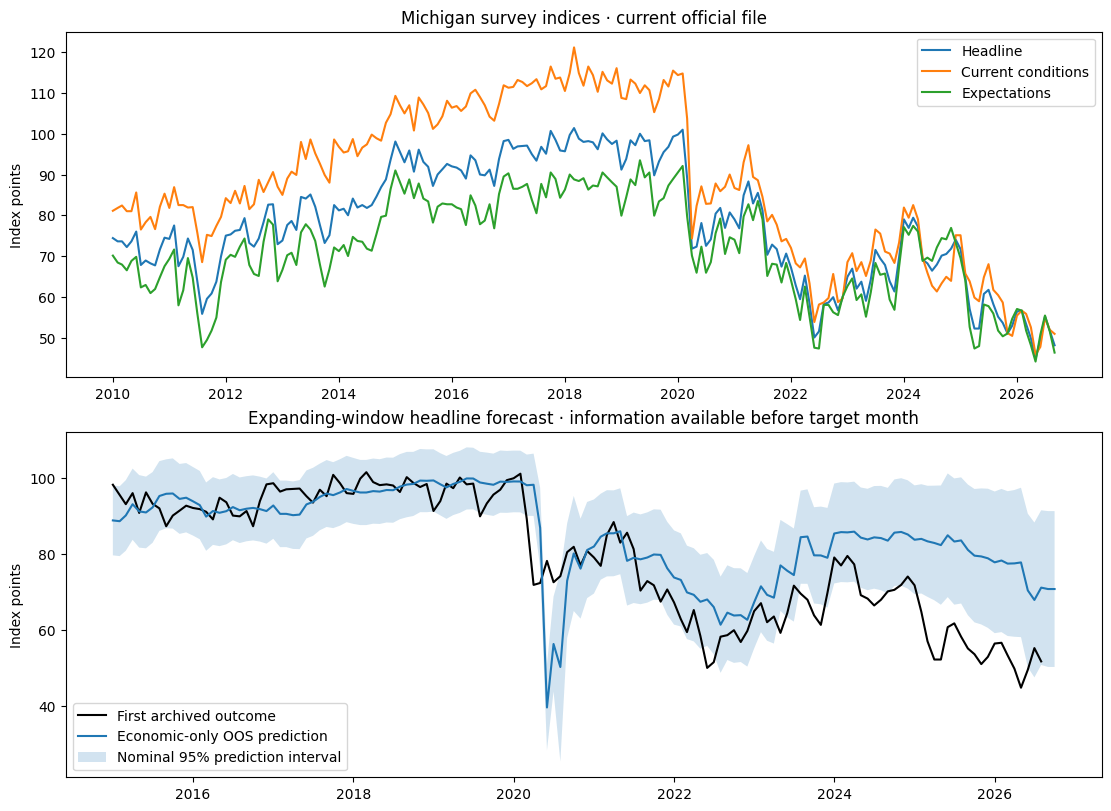

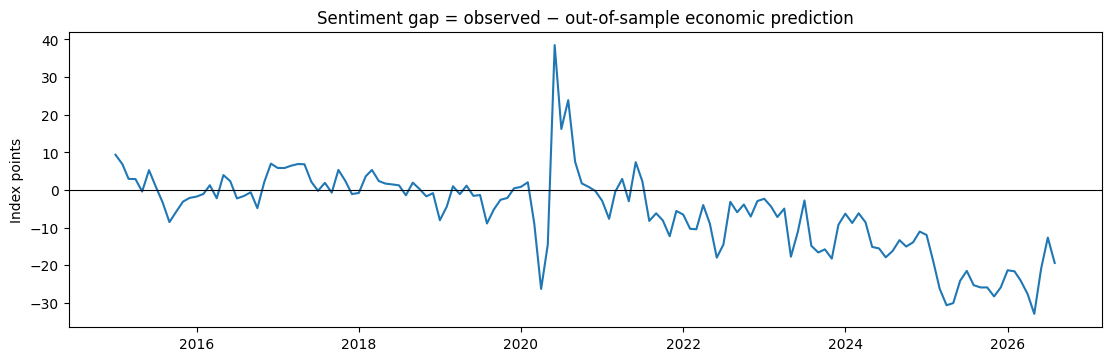

In [ ]:
def score_models(pred):
    reports=[]
    for target,g in pred.groupby('target'):
        complete=g.loc[g.actual.notna()]
        counts=complete.groupby('observation_month').model.nunique()
        all_models=complete.model.nunique()
        common=counts.index[counts.eq(all_models)]
        common_frame=complete.loc[complete.observation_month.isin(common)]
        for sample,frame in [('all_common_months',common_frame),
                             ('excluding_pandemic_target_months',common_frame.loc[~common_frame.observation_month.between('2020-03-01','2021-12-01')])]:
            for model,x in frame.groupby('model'):
                e=x.actual-x.predicted
                row=dict(target=target,model=model,sample=sample,n=len(x),rmse=float(np.sqrt(np.mean(e**2))),
                         mae=float(e.abs().mean()),mean_gap=float(e.mean()))
                for low,high,name in [('pi_lower','pi_upper','ols'),('empirical_lower','empirical_upper','empirical')]:
                    if low in x and high in x:
                        z=x.dropna(subset=[low,high])
                        row[name+'_interval_n']=len(z)
                        row[name+'_coverage']=float(z.actual.between(z[low],z[high]).mean()) if len(z) else np.nan
                        row[name+'_mean_width']=float((z[high]-z[low]).mean()) if len(z) else np.nan
                reports.append(row)
    return pd.DataFrame(reports)
metrics=score_models(predictions)
metrics.to_csv(RESULTS/'model_comparison_common_months.csv',index=False)
display(metrics)

# Control-specific gap changes, all on matching months; never switch the primary series silently.
released=predictions.loc[predictions.actual.notna()]
gaps=released.pivot(index=['target','observation_month'],columns='model',values='sentiment_gap')
gaps.to_csv(RESULTS/'gap_control_sensitivity.csv')

fig,axes=plt.subplots(2,1,figsize=(11,8),layout='constrained')
for col,label in [('sentiment','Headline'),('current_conditions','Current conditions'),('expectations','Expectations')]:
    axes[0].plot(survey_current.observation_month,survey_current[col],label=label)
axes[0].set(title='Michigan survey indices · current official file',ylabel='Index points');axes[0].legend()
p=primary.loc[primary.target.eq('sentiment')].sort_values('observation_month')
axes[1].plot(p.observation_month,p.actual,label='First archived outcome',color='black')
axes[1].plot(p.observation_month,p.predicted,label='Economic-only OOS prediction')
axes[1].fill_between(p.observation_month,p.pi_lower,p.pi_upper,alpha=.2,label='Nominal 95% prediction interval')
axes[1].set(title='Expanding-window headline forecast · information available before target month',ylabel='Index points');axes[1].legend()
fig.savefig(RESULTS/'survey_and_forecast.png',dpi=160)
plt.show()
fig,ax=plt.subplots(figsize=(11,3.5),layout='constrained')
ax.plot(p.observation_month,p.sentiment_gap);ax.axhline(0,color='black',linewidth=.8)
ax.set(title='Sentiment gap = observed − out-of-sample economic prediction',ylabel='Index points')
fig.savefig(RESULTS/'sentiment_gap.png',dpi=160);plt.show()

## 8. Reproducibility, updates and interpretation
**Reproduce:** keep `SNAPSHOT_ID`, configuration, raw responses and the notebook together. Rerunning uses cached raw responses. Keys are required only for responses not cached. The run manifest contains hashes and environment versions.

**Update:** choose a new snapshot ID and set `AS_OF` to the new retrieval date; rerun top to bottom. A fresh snapshot downloads updated official histories, including revisions, and recomputes archive information sets. Older snapshots remain untouched. Downloads are small economic series, so a full refresh is intentional. Never append new vintages to an old forecast file or overwrite old raw responses. Compare snapshots using the exported predictions and revision ledgers. Changes to source archives can change reconstructed historical information sets; preserve the old forecasts to audit this.

**Interpretation:** falling inflation means prices rise more slowly; it does not reverse previous price increases. Cumulative-price measures can capture persistent affordability concerns. National GDP growth need not track a household's real income, housing costs, debt burden or job insecurity. Michigan's questions cover more than the three baseline statistics. A negative gap is **unexplained pessimism conditional on this model and information set**, not proof of perceptual bias, media influence or irrationality.

**Before submission:** review the publication-date audit and archive coverage, identify the exact target release concept, inspect the 2026 monitoring rows for unavailable outcomes, report interval coverage and source limitations, and acknowledge potential survey-method changes or structural breaks. Do not infer preliminary/final stage from an archive revision number. Component descriptive charts are not component forecasts. No component forecast is claimed without its historical release data.

**Handoff to the headline module:** join on `observation_month` and retain `forecast_origin`/`information_cutoff`. Use lagged headline measures collected before that origin for forecasting. Same-month media-gap associations are descriptive unless a different temporal design is explicitly specified. Keep an economics-only baseline and compare additional-media models on the same chronological evaluation months.

In [ ]:
# Save schema, computational environment and integrity manifest.
output_dictionary={
 'monthly_current_official.csv':'Current survey, U-3, PCE levels and YoY; not vintage-safe predictors',
 'gdp_current_quarterly_growth.csv':'Quarterly levels and two distinct GDP growth definitions',
 'survey_three_indices_current.csv':'Separate headline, current-conditions and expectations histories',
 'monthly_information_sets.csv':'Frozen feature values, observation periods, vintage dates and origins',
 'all_revision_records.csv':'Archive validity intervals, revision numbers and publication-date provenance',
 'survey_forecast_outcomes.csv':'Explicit target value, stage and availability date',
 'out_of_sample_predictions.csv':'Predictions, prediction intervals, actuals, gaps and coefficients',
 'sentiment_gap_primary.csv':'Pre-specified economic_core gap series',
 'monitoring_window_2026.csv':'Focused window; unavailable outcomes remain missing',
 'model_comparison_common_months.csv':'Errors and interval coverage on identical evaluation months'}
(RESULTS/'output_dictionary.json').write_text(json.dumps(output_dictionary,indent=2))
versions={p:importlib.metadata.version(p) for p in ['pandas','numpy','scipy','matplotlib']}
manifest=dict(config=CONFIG,python=platform.python_version(),packages=versions,
    generated_at_utc=datetime.now(ZoneInfo('UTC')).isoformat(),files=[])
for folder in [RAW,PROCESSED,RESULTS]:
    for path in sorted(folder.glob('*')):
        if path.is_file() and path.name!='run_manifest.json':
            manifest['files'].append(dict(path=str(path.relative_to(BASE)),size_bytes=path.stat().st_size,
                sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Module complete. Main handoff:',RESULTS/'sentiment_gap_primary.csv')
print('Monitoring window:',RESULTS/'monitoring_window_2026.csv')

Module complete. Main handoff: /content/drive/MyDrive/NLP-FinalProject/01_economic_baseline/results/2026-10-16/sentiment_gap_primary.csv
Monitoring window: /content/drive/MyDrive/NLP-FinalProject/01_economic_baseline/results/2026-10-16/monitoring_window_2026.csv


### Official documentation
- [Michigan tables and downloadable histories](https://www.sca.isr.umich.edu/tables.html)
- [BLS Public Data API v2](https://www.bls.gov/developers/api_signature_v2.htm)
- [BEA PCE price index](https://www.bea.gov/data/personal-consumption-expenditures-price-index)
- [BEA GDP](https://www.bea.gov/data/gdp/gross-domestic-product)
- [BEA API guide](https://apps.bea.gov/api/_pdf/bea_web_service_api_user_guide.pdf)
- [FRED observations and vintage parameters](https://fred.stlouisfed.org/docs/api/fred/series_observations.html)
- [FRED real-time periods](https://fred.stlouisfed.org/docs/api/fred/realtime_period.html)
- [FRED release dates](https://fred.stlouisfed.org/docs/api/fred/release_dates.html)

This module was built and checked with synthetic revision scenarios; remote authenticated API collection must be run with your keys. It does not ship invented economic observations or empirical forecast results.